# **Linear Regression**
Linear regression finds the straight line (or plane, with several features) that sits closest to your data, then uses it to predict a number. The algorithm is the method for finding that line. It has four parts.

## **1. The model**

- For one feature: ``ŷ = β₀ + β₁x``. For several: ``ŷ = β₀ + β₁x₁ + β₂x₂ + ...``

``ŷ (“y-hat”)`` is the prediction, ``β₀`` is the intercept, and the other ``β`` values are the weights that the algorithm has to find.

## **2. The cost function**

To decide which line is best, you need a score for how wrong a line is. For each row, the residual is ``y - ŷ (actual minus predicted)``. The algorithm squares each residual and adds them up:

``SSE = Σ (yᵢ - ŷᵢ)²``

Dividing by the number of rows gives the mean squared error (MSE). Squaring stops positive and negative errors cancelling, and it punishes big misses more than small ones. The best line is the one with the lowest cost.

## **3. Finding the best weights**

There are two standard ways to minimise the cost.
**Closed-form solution (ordinary least squares)**. The cost is a smooth bowl-shaped curve with a single lowest point, so calculus gives the answer directly: ``β = (XᵀX)⁻¹Xᵀy``, called the normal equation. This is what scikit-learn’s LinearRegression uses (in practice with a more stable numerical method). It is exact and has no settings to tune. It gets slow when you have a very large number of features.

**Gradient descent**. This is an iterative method, and it is the same idea used to train neural networks:

1 - Start with guesses for the weights (for example, all zeros).

2 - Compute the gradient, the direction in which the cost rises fastest.

3 - Move each weight a small step the opposite way, scaled by the learning rate: ``β ← β - learning_rate × gradient``.

4 - Repeat until the cost stops falling.

The learning rate matters. If it is too small, training is slow. If it is too large, the steps overshoot and the cost can grow instead of shrink. Gradient descent also works much better when features are scaled to similar ranges. In scikit-learn this version is SGDRegressor.

# **4. Assumptions**

Linear regression gives trustworthy results when these roughly hold:

**Linearity**: the relationship between features and target is roughly a straight line.

**Independence**: rows don’t influence each other.

**Constant error spread**: the size of the errors is similar across the range of predictions.

**Roughly normal errors**: this matters mainly for confidence intervals and significance tests, not for the fit itself.
No strong correlation between features: otherwise the individual weights become unstable.

# **5. Common variations**
**Polynomial regression**: adds terms like ``x²`` so the model can fit curves while remaining linear in the weights.

**Ridge (L2) and Lasso (L1)**: add a penalty on large weights to reduce overfitting. Lasso can shrink some weights to exactly zero, which acts as feature selection.

## Predicting the team position givens their goals scored
#### Train a model that predict the rank of the team due to goal scored, using the data of primer league seasons from 1996 to 2020

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('historical_prem_standings.csv')

In [5]:
df.head()

,Rk,Squad,MP,W,D,L,GF,GA,Pts,Attendance,Top Team Scorer,Goalkeeper,Year
0,1,Manchester Utd,38,25,7,6,73,35,82,41001,Eric Cantona - 14,Peter Schmeichel,1996
1,2,Newcastle Utd,38,24,6,8,66,37,78,36501,Les Ferdinand - 25,Shaka Hislop,1996
2,3,Liverpool,38,20,11,7,70,34,71,39553,Robbie Fowler - 28,David James,1996
3,4,Aston Villa,38,18,9,11,52,35,63,37492,Dwight Yorke - 17,Mark Bosnich,1996
4,5,Arsenal,38,17,12,9,49,32,63,32614,Ian Wright - 15,David Seaman,1996


In [6]:
df.shape

(500, 13)

In [3]:
X = df['GF'].values.reshape(-1, 1)  # Reshape for sklearn
y = df['Rk'].values

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**LinearRegression** in scikit-learn is ordinary least squares (OLS). It finds the straight line (or flat plane, with several features) that gives the smallest total squared error on your training data.

**What it computes**

For features X and target y, it finds the coefficients β that minimise:

``Σ (yᵢ − ŷᵢ)² where ŷ = β₀ + β₁x₁ + β₂x₂ + ...``

This has a closed-form solution, the normal equation ``β = (XᵀX)⁻¹ Xᵀy``. Scikit-learn doesn’t invert the matrix directly, because that is numerically fragile. It uses a more stable least-squares solver (scipy.linalg.lstsq, based on the singular value decomposition) that reaches the same answer. Two consequences follow:

It is not iterative. There is no learning rate, no number of epochs and no gradient descent, so it is fast and gives the same result every time.
If features are perfectly correlated, the solver still returns a result (the smallest-norm one) instead of crashing, but the individual coefficients stop being meaningful.

X must be 2D (even with one feature, use df[["GF"]] with double brackets, or .reshape(-1, 1) for an array). y is normally 1D.

| Parameter | Default | What it does |
| --- | --- | --- |
| fit_intercept | True | Learns β₀. Set to False only if the line should pass through the origin. |
| copy_X | True | Copies X rather than overwriting it. |
| n_jobs | None | Parallel jobs. It only helps in special cases (several targets with sparse data, or positive=True), so you can ignore it. |
| positive | False | Forces all coefficients to be non-negative. |

Notice what is missing: there are no alpha or regularisation settings. Plain LinearRegression does not penalise large coefficients.

**Attributes and methods**

| Attribute / method | Meaning |
| --- | --- |
| `coef_` | The learned slopes, one per feature. |
| `intercept_` | The learned intercept. |
| `rank_` and `singular_` | Information about the matrix, useful for spotting correlated features. |
| `feature_names_in_` | Column names, if you trained on a DataFrame. |
| `fit(X, y)` | Learns the coefficients. |
| `predict(X)` | Returns predictions. |
| `score(X, y)` | Returns R². |

In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.32]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.79
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[294.35]


In [6]:
y_pred = lr.predict(X_test)

In [7]:
accuracy = lr.score(X_test, y_test)
accuracy

0.632619348267969

In [8]:
# Display the linear regression coefficients
# slope is the coefficient of the independent variable (GF)
slope = lr.coef_[0]
print(f"Slope (Coefficient): {slope:.2f}")

# Intercept is the value of the dependent variable (Rk) when the independent variable (GF) is zero. 
# It represents the point where the regression line crosses the y-axis.
intercept = lr.intercept_
print(f"Intercept: {intercept:.2f}")

# the regression line can be represented by the equation: Rk = slope * GF + intercept
print(f"Regression Line Equation: Rk = {slope:.2f} * GF + {intercept:.2f}")

# if the GF is 80, we can predict the Rk using the regression line equation
predicted_rk = slope * 80 + intercept
predicted_rk

Slope (Coefficient): -0.32
Intercept: 26.79
Regression Line Equation: Rk = -0.32 * GF + 26.79


np.float64(0.9318360221491808)

In [9]:
# R-squared value (coefficient of determination) is a statistical measure that represents the proportion 
# of the variance for a dependent variable (Rk) that's explained by an independent variable (GF) in a regression model.
# It provides an indication of how well the independent variable (GF) explains the variability of the dependent variable (Rk). 
# The R-squared value ranges from 0 to 1, where:
# - 0 indicates that the model does not explain any of the variability of the response data around its mean.
# - 1 indicates that the model explains all the variability of the response data around its mean 
R_squared = lr.score(X, y)
print(f"R-squared value: {R_squared:.2f}")

R-squared value: 0.66


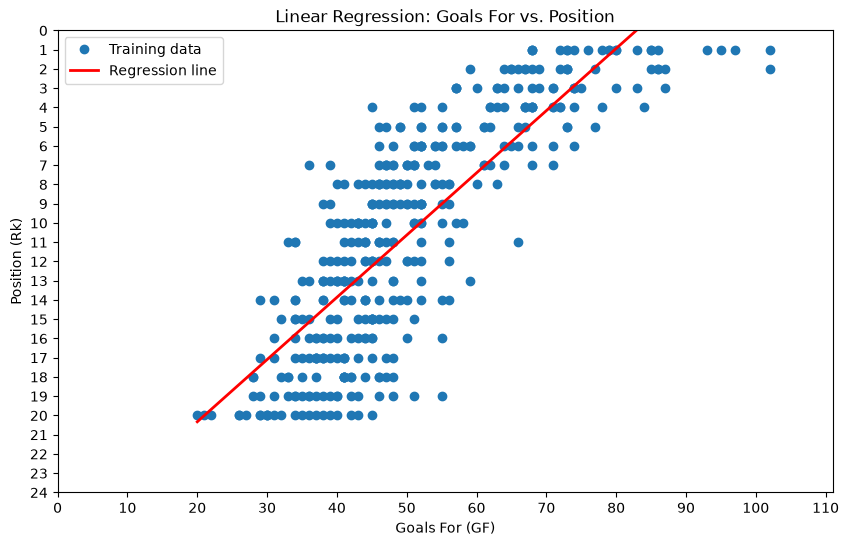

In [41]:
import numpy as np

model = LinearRegression()
model.fit(X_train, y_train)

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.figure(figsize=(10, 6))

plt.plot(X_train, y_train, 'o', label='Training data')
plt.plot(x_line, y_line, color='red', linewidth=2, label='Regression line')
plt.xlabel('Goals For (GF)')
plt.ylabel('Position (Rk)')
plt.ylim(0, 24)
plt.yticks(np.arange(0, 25, 1))
plt.xlim(0, 111)
plt.xticks(np.arange(0, 112, 10))
plt.title('Linear Regression: Goals For vs. Position')
plt.legend()
plt.gca().invert_yaxis()
plt.show()

**Reading the plot**
- Each dot is one team in one season. Its horizontal position is the goals it scored and its vertical position is where it finished. With the y-axis inverted, rank 1 is at the top, so the best teams sit in the top right.

- The cloud runs from bottom-left to top-right. Teams that score more finish higher, so goals for and league position are clearly related.

- The red line is the model’s prediction for any number of goals. It is the single straight line closest to all the dots, with the squared vertical gaps added up and made as small as possible. Dots end up scattered roughly evenly above and below it.

**What the plot reveals**
- The spread is large. At around 45 goals, teams finished anywhere from 4th to 20th. Goals scored alone tells you roughly where a team will finish, but not exactly.

- The outliers show what is missing. The team near 55 goals that finished 19th and the team near 36 goals that finished 7th are likely cases where the other half of the game decided the season. Goals against, or goal difference, would explain much of that scatter.

| Problem | Use |
| --- | --- |
| Coefficients too large or unstable, correlated features | Ridge (shrinks coefficients) |
| Many features, you want some dropped | Lasso (sets some coefficients to zero) |
| A curved relationship | PolynomialFeatures + LinearRegression |
| Very large dataset | SGDRegressor (iterative, scales better) |
| Predicting a yes/no outcome | LogisticRegression (classification, as in xG models) |

# **Model Evaluation in Linear Regression**
Model Evaluation in Linear Regression is the process of measuring how accurately a Linear Regression model predicts continuous numerical values and how well it explains the relationship between independent variables (X) and the dependent variable (Y).

The model tries to find the best-fit line by minimizing the sum of squared residuals (errors).

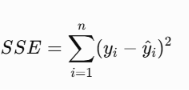

A residual is the difference between the actual value and the predicted value.

# **2. Linear Regression Evaluation Metrics**
There are six important metrics.

### **1. MAE (Mean Absolute Error)**
Measures the average absolute difference between actual and predicted values.

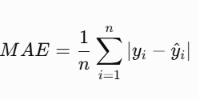

In [12]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae:.2f}")

Mean Absolute Error (MAE): 2.87


### **2. MSE (Mean Squared Error)**
Measures the average squared difference between actual and predicted values.
Lower is better.

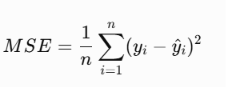

In [11]:
# mean squared error (MSE) is a common measure of the quality of a linear regression model.
# It represents the average of the squared differences between the predicted values and the actual values.
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")

Mean Squared Error (MSE): 11.52


### **3. RMSE (Root Mean Squared Error)**
The square root of MSE.

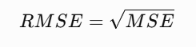

### **4. R² (R-Squared / Coefficient of Determination)**

Measures how much of the variation in the dependent variable is explained by the model.

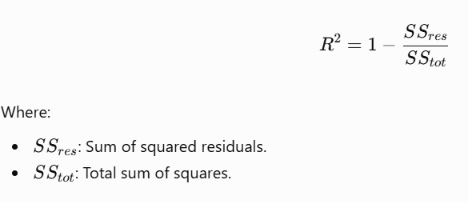

### **5. Adjusted R²**
Adjusted R² is similar to R², but it considers the number of independent variables used in the model.

Why is it important?

Imagine you have a model predicting house prices:
- Model 1: Area and bedrooms.
- Model 2: Area, bedrooms, bathrooms, and 20 additional variables.
Adding more variables can increase R² even if those variables are not useful.

Adjusted R² penalizes unnecessary predictors.

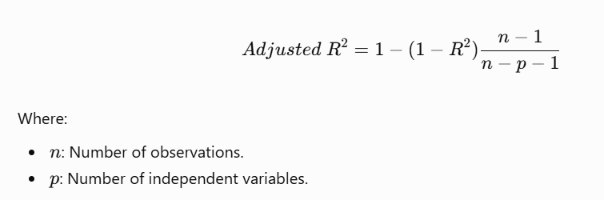

### **6. MAPE (Mean Absolute Percentage Error)**
Measures the average prediction error as a percentage of actual values.

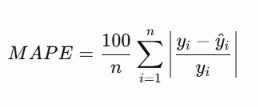

For example, MAPE = 5% means the average absolute percentage error is 5%.

**Important**: MAPE is not suitable when actual values are zero and can behave poorly when actual values are close to zero.

### **Comparison Between Evaluation Metrics**

| Metric | What it measures | Best result |
| --- | --- | --- |
| MAE | Average absolute error | Lower |
| MSE | Average squared error | Lower |
| RMSE | Error in original units | Lower |
| R² | Explained variation | Higher |
| Adjusted R² | Explained variation adjusted for predictors | Higher |
| MAPE | Average percentage error | Lower |

### Evaluating Linear Regression Matrices in Sklearn

In [20]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2:", round(r2, 2))
print("MAPE:", round(mape, 2), "%")

MAE: 2.87
MSE: 11.52
RMSE: 3.39
R2: 0.63
MAPE: 61.27 %


## **Question & Answers**
| Question | Key answer |
|---|---|
| How do you measure regression performance? | MAE, MSE, RMSE, and R² |
| What is the difference between MAE and MSE? | MSE penalizes large errors more. |
| What is the difference between R² and adjusted R²? | Adjusted R² accounts for the number of predictors. |
| How do you detect overfitting? | Compare training and testing performance. |
| How do you check linear regression assumptions? | Analyze the residuals. |
| How do you detect multicollinearity? | Use VIF. |
| Why use cross-validation? | It provides a more robust performance estimate. |